# Mechanism inspection: GP and Neural Net

Goal: visualise how nonlinear `GPMechanism` and `NeuralNetMechanism` actually are,
and understand what knobs control the degree of nonlinearity.

In [5]:
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from mcd.mechanisms import (
    GPMechanism, ANMGPMechanism, NeuralNetMechanism, NeuralNetANM,
    _N_HIDDEN, _N_DEPTH, _N_RFF, _GP_LENGTH_SCALE, build_mechanism
)

rng = np.random.default_rng(0)
x1d = np.linspace(-3, 3, 300).reshape(-1, 1)  # 1-parent sweep
s0   = np.zeros(300)                            # noise = 0  → pure mean
print('defaults: N_HIDDEN =', _N_HIDDEN, '  N_DEPTH =', _N_DEPTH, '  N_RFF =', _N_RFF, '  GP_LENGTH_SCALE =', _GP_LENGTH_SCALE)

defaults: N_HIDDEN = 64   N_DEPTH = 8   N_RFF = 32   GP_LENGTH_SCALE = 1.0


## 1. GP mechanisms — mean function and source sensitivity

With s=0: `x = f(pa, 0)` — the pure mean function.

**GP (non-additive)**: `x = RFF([pa, s]) + c_s * s`. `s` enters the RFF nonlinearly alongside parents; `c_s` sets a monotonicity floor on source sensitivity.

**ANM-GP (additive)**: `x = RFF(pa) + s`. `s` enters purely additively, so source sensitivity is identically 1 everywhere.

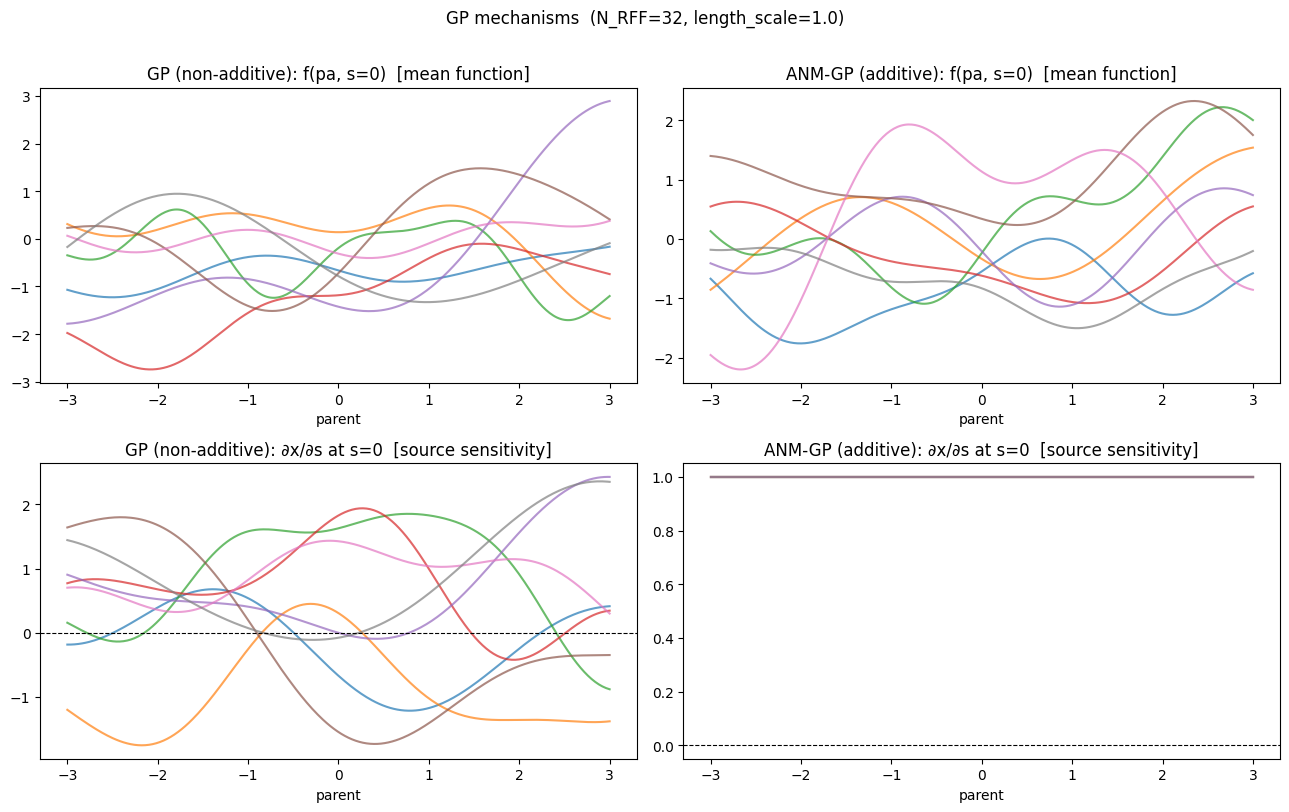

In [6]:
N_DRAWS = 8
eps_s = 1e-4
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for col, (key, label) in enumerate([('gp', 'GP (non-additive)'), ('anm_gp', 'ANM-GP (additive)')]):
    for _ in range(N_DRAWS):
        mech = build_mechanism(key, n_parents=1, rng=rng)
        mean_fn = mech(x1d, s0)
        dsens = (mech(x1d, np.full(300, eps_s)) - mech(x1d, np.full(300, -eps_s))) / (2 * eps_s)
        axes[0, col].plot(x1d.ravel(), mean_fn, alpha=0.7)
        axes[1, col].plot(x1d.ravel(), dsens, alpha=0.7)
    axes[0, col].set_title(f'{label}: f(pa, s=0)  [mean function]')
    axes[0, col].set_xlabel('parent')
    axes[1, col].set_title(f'{label}: ∂x/∂s at s=0  [source sensitivity]')
    axes[1, col].set_xlabel('parent')
    axes[1, col].axhline(0, color='k', lw=0.8, ls='--')

fig.suptitle(f'GP mechanisms  (N_RFF={_N_RFF}, length_scale={_GP_LENGTH_SCALE})', y=1.01)
plt.tight_layout()
plt.show()

## 2. Neural Net (non-additive) — mean function and source sensitivity

With s=0: `x = deep_MLP(pa, s=0)` — this is the 'mean' curve.
Source sensitivity ∂x/∂s is computed numerically via finite differences.

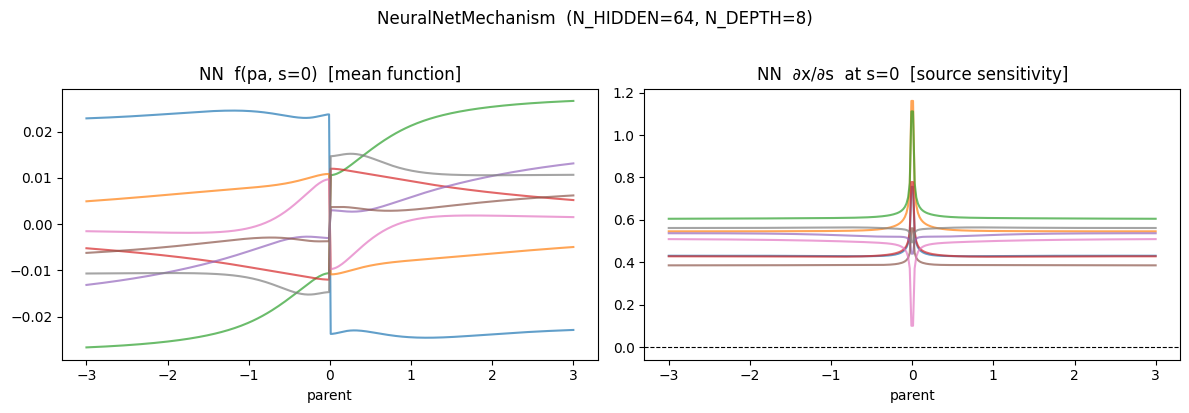

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
eps_s = 1e-4

for _ in range(N_DRAWS):
    nn = build_mechanism('nn', n_parents=1, rng=rng)
    mean_fn = nn(x1d, s0)
    # numerical ∂x/∂s at s=0
    dsens = (nn(x1d, np.full(300,  eps_s)) - nn(x1d, np.full(300, -eps_s))) / (2 * eps_s)
    axes[0].plot(x1d.ravel(), mean_fn, alpha=0.7)
    axes[1].plot(x1d.ravel(), dsens,   alpha=0.7)

axes[0].set_title('NN  f(pa, s=0)  [mean function]')
axes[0].set_xlabel('parent')
axes[1].set_title('NN  ∂x/∂s  at s=0  [source sensitivity]')
axes[1].set_xlabel('parent')
axes[1].axhline(0, color='k', lw=0.8, ls='--')
fig.suptitle(f'NeuralNetMechanism  (N_HIDDEN={_N_HIDDEN}, N_DEPTH={_N_DEPTH})', y=1.02)
plt.tight_layout()
plt.show()

## 3. Side-by-side: output vs linear baseline

Plot `f(pa, s=0) - f(0, 0)` (centred) alongside a pure linear function with the same
slope at the origin, to gauge how far each draw departs from linearity.

/tmp/ipykernel_2257551/1703410168.py:14: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y0 = float(mech(np.zeros((1, 1)), np.zeros(1)))
/tmp/ipykernel_2257551/1703410168.py:6: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return float((fn(pa_pos, s1) - fn(pa_neg, s1)) / (2 * eps))


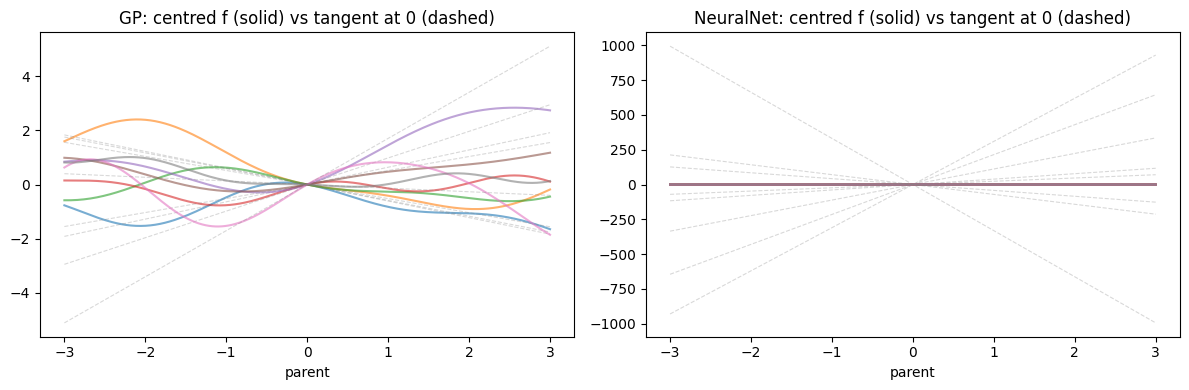

In [8]:
def slope_at_zero(fn, eps=1e-4):
    """Finite-difference slope at parent=0, s=0."""
    pa_pos = np.array([[eps]])
    pa_neg = np.array([[-eps]])
    s1 = np.zeros(1)
    return float((fn(pa_pos, s1) - fn(pa_neg, s1)) / (2 * eps))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, key, label in [(axes[0], 'gp', 'GP'), (axes[1], 'nn', 'NeuralNet')]:
    for _ in range(N_DRAWS):
        mech = build_mechanism(key, n_parents=1, rng=rng)
        y = mech(x1d, s0)
        y0 = float(mech(np.zeros((1, 1)), np.zeros(1)))
        k  = slope_at_zero(mech)
        nonlin = y - y0                 # centred output
        linear = k * x1d.ravel()        # linear reference with same slope
        ax.plot(x1d.ravel(), nonlin, alpha=0.6, label='_')
        ax.plot(x1d.ravel(), linear, alpha=0.3, lw=0.8, ls='--', color='gray')
    ax.set_title(f'{label}: centred f (solid) vs tangent at 0 (dashed)')
    ax.set_xlabel('parent')

plt.tight_layout()
plt.show()

## 4. Curvature histogram  (|f'' |  at s=0)

Larger curvature → more nonlinear.  Compare GP vs NN across many draws.

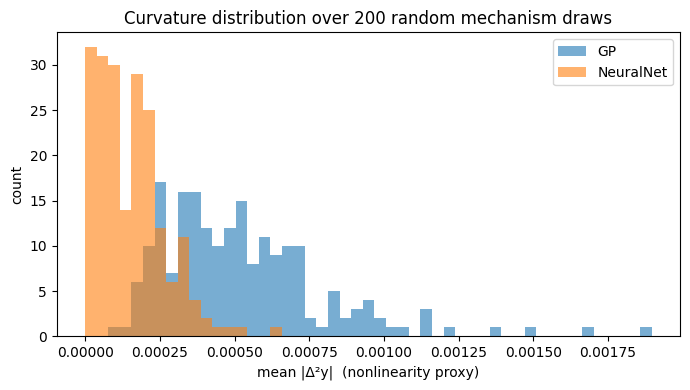

GP:  median=0.0005  90th=0.0009
NN:  median=0.0001  90th=0.0003


In [9]:
N_STAT = 200
eps = 1e-3
pa0 = np.zeros((1, 1))
s1  = np.zeros(1)

def mean_abs_curvature(mech, x_grid, s0):
    """Mean |second finite diff| over the grid as a nonlinearity proxy."""
    y = mech(x_grid, s0)
    d2 = np.diff(y, n=2)
    return float(np.mean(np.abs(d2)))

curv_gp, curv_nn = [], []
for _ in range(N_STAT):
    curv_gp.append(mean_abs_curvature(build_mechanism('gp', 1, rng), x1d, s0))
    curv_nn.append(mean_abs_curvature(build_mechanism('nn', 1, rng), x1d, s0))

fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(0, max(max(curv_gp), max(curv_nn)), 50)
ax.hist(curv_gp, bins=bins, alpha=0.6, label='GP')
ax.hist(curv_nn, bins=bins, alpha=0.6, label='NeuralNet')
ax.set_xlabel('mean |Δ²y|  (nonlinearity proxy)')
ax.set_ylabel('count')
ax.set_title(f'Curvature distribution over {N_STAT} random mechanism draws')
ax.legend()
plt.tight_layout()
plt.show()

print(f'GP:  median={np.median(curv_gp):.4f}  90th={np.percentile(curv_gp,90):.4f}')
print(f'NN:  median={np.median(curv_nn):.4f}  90th={np.percentile(curv_nn,90):.4f}')

## 5. Tuning knobs

### GP: length scale controls how oscillatory mu is.
Larger length_scale → smoother → less nonlinear.

### NN: W1 scale controls the pre-activation magnitude.
Smaller W1 weights → pre-activations stay near 0 → tanh ≈ linear → less nonlinear.

Sweep both and plot the median curvature.

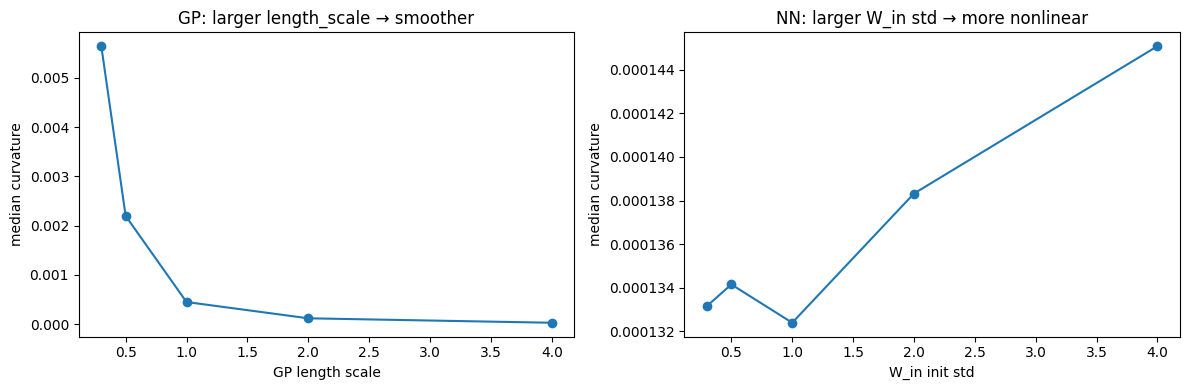

In [10]:
# --- GP length scale sweep ---
length_scales = [0.3, 0.5, 1.0, 2.0, 4.0]
N_S = 100

gp_med = []
for ls in length_scales:
    curv = []
    for _ in range(N_S):
        gp = GPMechanism(
            omega=rng.normal(0.0, 1.0 / ls, (_N_RFF, 2)),  # n_parents+1 = 2
            phase=rng.uniform(0.0, 2.0 * np.pi, _N_RFF),
            alpha=rng.normal(0.0, 1.0, _N_RFF),
            c_s=float(rng.uniform(0.3, 0.7)),
        )
        curv.append(mean_abs_curvature(gp, x1d, s0))
    gp_med.append(np.median(curv))

# --- NN W_in std sweep ---
w1_stds = [0.3, 0.5, 1.0, 2.0, 4.0]  # larger → more nonlinear
nn_med = []
for std in w1_stds:
    curv = []
    for _ in range(N_S):
        nn = NeuralNetMechanism(
            W_in=rng.normal(0, std, (_N_HIDDEN, 1)),
            w_s=rng.uniform(0.3, 0.7, _N_HIDDEN),
            b_in=np.zeros(_N_HIDDEN),
            hidden_weights=[rng.normal(0, 1/np.sqrt(_N_HIDDEN), (_N_HIDDEN, _N_HIDDEN)) for _ in range(_N_DEPTH - 2)],
            hidden_biases=[np.zeros(_N_HIDDEN) for _ in range(_N_DEPTH - 2)],
            out_weight=rng.uniform(0.3, 0.7, _N_HIDDEN) / _N_HIDDEN,
            ln_gamma=np.ones(_N_HIDDEN),
            ln_beta=np.zeros(_N_HIDDEN),
            c_s=float(rng.uniform(0.3, 0.7)),
        )
        curv.append(mean_abs_curvature(nn, x1d, s0))
    nn_med.append(np.median(curv))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(length_scales, gp_med, 'o-')
axes[0].set_xlabel('GP length scale')
axes[0].set_ylabel('median curvature')
axes[0].set_title('GP: larger length_scale → smoother')

axes[1].plot(w1_stds, nn_med, 'o-')
axes[1].set_xlabel('W_in init std')
axes[1].set_ylabel('median curvature')
axes[1].set_title('NN: larger W_in std → more nonlinear')

plt.tight_layout()
plt.show()

## 6. 2-D parent: surface plot

Check that the 2-parent case looks reasonable (not degenerate).

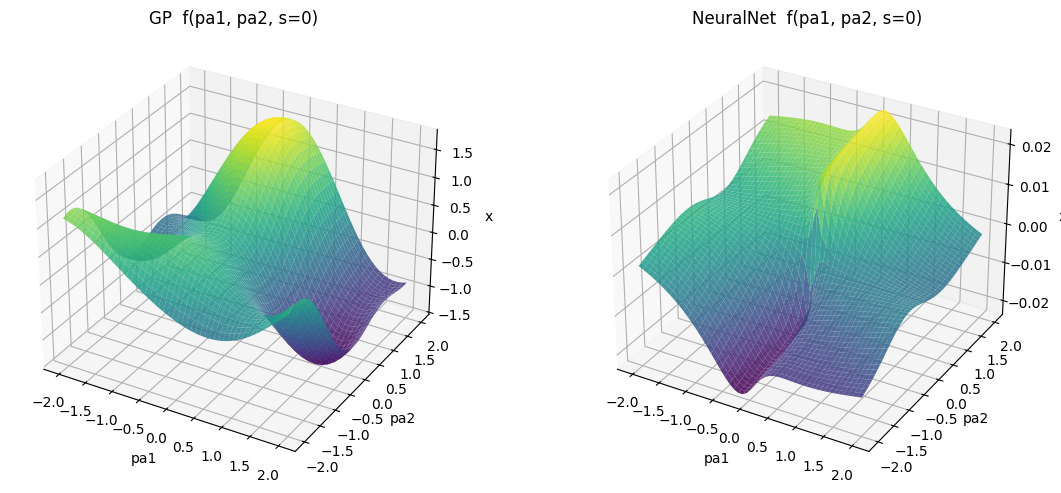

In [11]:
grid_1d = np.linspace(-2, 2, 50)
pa1, pa2 = np.meshgrid(grid_1d, grid_1d)
pa2d = np.stack([pa1.ravel(), pa2.ravel()], axis=1)  # (2500, 2)
s2d  = np.zeros(len(pa2d))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), subplot_kw={'projection': '3d'})

for ax, key, label in [(axes[0], 'gp', 'GP'), (axes[1], 'nn', 'NeuralNet')]:
    mech = build_mechanism(key, n_parents=2, rng=rng)
    z = mech(pa2d, s2d).reshape(50, 50)
    ax.plot_surface(pa1, pa2, z, cmap='viridis', alpha=0.85)
    ax.set_title(f'{label}  f(pa1, pa2, s=0)')
    ax.set_xlabel('pa1'); ax.set_ylabel('pa2'); ax.set_zlabel('x')

plt.tight_layout()
plt.show()

## 6b. 1-parent surface: f(pa, s)

Both axes sweep together — parent on x, source on y — so you can see how the mechanism interacts the two inputs.

In [ ]:
grid_1d_ps = np.linspace(-2, 2, 50)
pa_vals, s_vals = np.meshgrid(grid_1d_ps, grid_1d_ps)
pa_1d = pa_vals.ravel().reshape(-1, 1)   # (2500, 1)
s_1d  = s_vals.ravel()                   # (2500,)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), subplot_kw={'projection': '3d'})

for ax, key, label in [(axes[0], 'gp', 'GP'), (axes[1], 'nn', 'NeuralNet')]:
    mech = build_mechanism(key, n_parents=1, rng=rng)
    z = mech(pa_1d, s_1d).reshape(50, 50)
    ax.plot_surface(pa_vals, s_vals, z, cmap='viridis', alpha=0.85)
    ax.set_title(f'{label}  f(pa, s)')
    ax.set_xlabel('parent'); ax.set_ylabel('source'); ax.set_zlabel('x')

plt.tight_layout()
plt.show()

## 7. GP: controlling nonlinearity

Two independent knobs:
- **Length scale** (larger → smoother mean function and source sensitivity)
- **`c_s`** (larger → higher floor on source sensitivity → mechanism stays more monotone in s)

Rows: different length scales. Columns: mean function and source sensitivity.

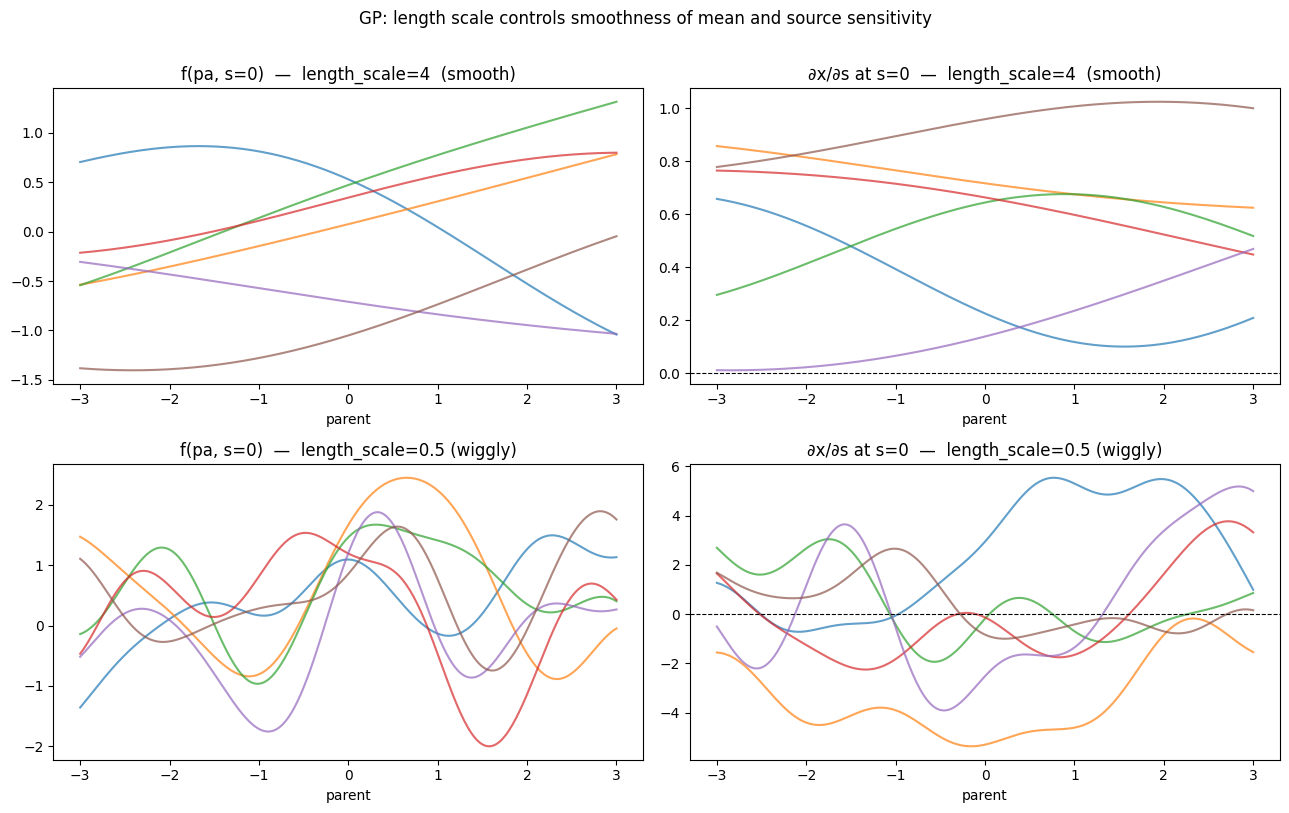

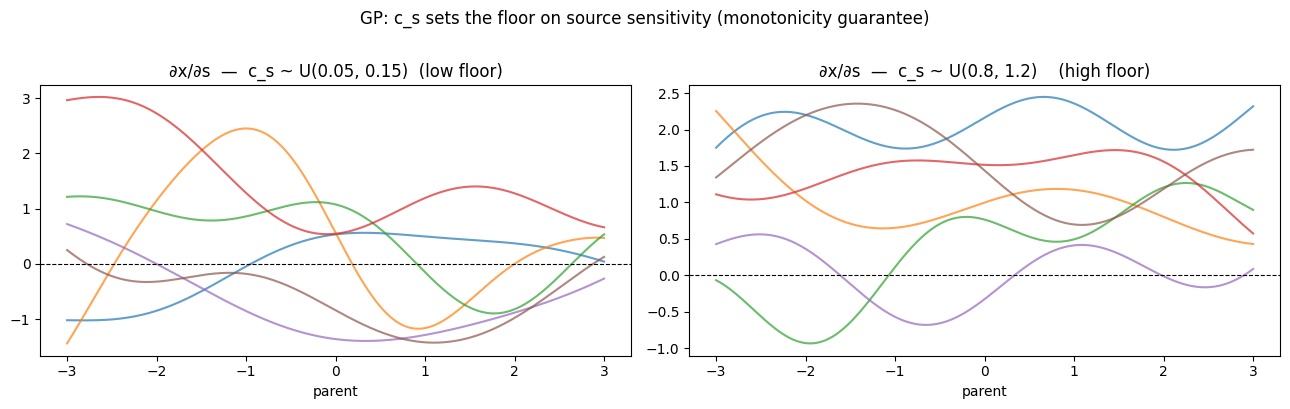

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
N_DRAWS = 6
eps_s = 1e-4

configs = [
    dict(ls=4.0, label='length_scale=4  (smooth)'),
    dict(ls=0.5, label='length_scale=0.5 (wiggly)'),
]

rng2 = np.random.default_rng(1)
for row, cfg in enumerate(configs):
    ls, label = cfg['ls'], cfg['label']
    for _ in range(N_DRAWS):
        gp = GPMechanism(
            omega=rng2.normal(0, 1/ls, (_N_RFF, 2)),
            phase=rng2.uniform(0, 2*np.pi, _N_RFF),
            alpha=rng2.normal(0, 1.0, _N_RFF),
            c_s=float(rng2.uniform(0.3, 0.7)),
        )
        mean_fn = gp(x1d, np.zeros(300))
        dsens = (gp(x1d, np.full(300, eps_s)) - gp(x1d, np.full(300, -eps_s))) / (2 * eps_s)
        axes[row, 0].plot(x1d.ravel(), mean_fn, alpha=0.7)
        axes[row, 1].plot(x1d.ravel(), dsens, alpha=0.7)
    axes[row, 0].set_title(f'f(pa, s=0)  —  {label}')
    axes[row, 0].set_xlabel('parent')
    axes[row, 1].set_title(f'∂x/∂s at s=0  —  {label}')
    axes[row, 1].set_xlabel('parent')
    axes[row, 1].axhline(0, color='k', lw=0.8, ls='--')

fig.suptitle('GP: length scale controls smoothness of mean and source sensitivity', y=1.01)
fig.tight_layout()

# Second figure: c_s floor effect on source sensitivity
fig2, axes2 = plt.subplots(1, 2, figsize=(13, 4))
rng_cs = np.random.default_rng(42)
for ax, (c_lo, c_hi, c_label) in zip(axes2, [
    (0.05, 0.15, 'c_s ~ U(0.05, 0.15)  (low floor)'),
    (0.8,  1.2,  'c_s ~ U(0.8, 1.2)    (high floor)'),
]):
    for _ in range(N_DRAWS):
        gp = GPMechanism(
            omega=rng_cs.normal(0, 1.0, (_N_RFF, 2)),
            phase=rng_cs.uniform(0, 2*np.pi, _N_RFF),
            alpha=rng_cs.normal(0, 1.0, _N_RFF),
            c_s=float(rng_cs.uniform(c_lo, c_hi)),
        )
        dsens = (gp(x1d, np.full(300, eps_s)) - gp(x1d, np.full(300, -eps_s))) / (2 * eps_s)
        ax.plot(x1d.ravel(), dsens, alpha=0.7)
    ax.axhline(0, color='k', lw=0.8, ls='--')
    ax.set_title(f'∂x/∂s  —  {c_label}')
    ax.set_xlabel('parent')

fig2.suptitle('GP: c_s sets the floor on source sensitivity (monotonicity guarantee)', y=1.01)
fig2.tight_layout()
plt.show()

## 8. NN: reducing nonlinearity

The single dominant knob is **W1 init std**.

- Large std → `pa @ W1.T` is large → tanh saturates → strongly nonlinear S-shaped output.
- Small std → `pa @ W1.T` is small → tanh ≈ identity → output nearly linear in pa.

We show 3 regimes side by side: near-linear, moderate, strongly nonlinear.

/tmp/ipykernel_2257551/2702519323.py:26: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  y0 = float(nn(np.zeros((1, 1)), np.zeros(1)))
/tmp/ipykernel_2257551/1703410168.py:6: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return float((fn(pa_pos, s1) - fn(pa_neg, s1)) / (2 * eps))


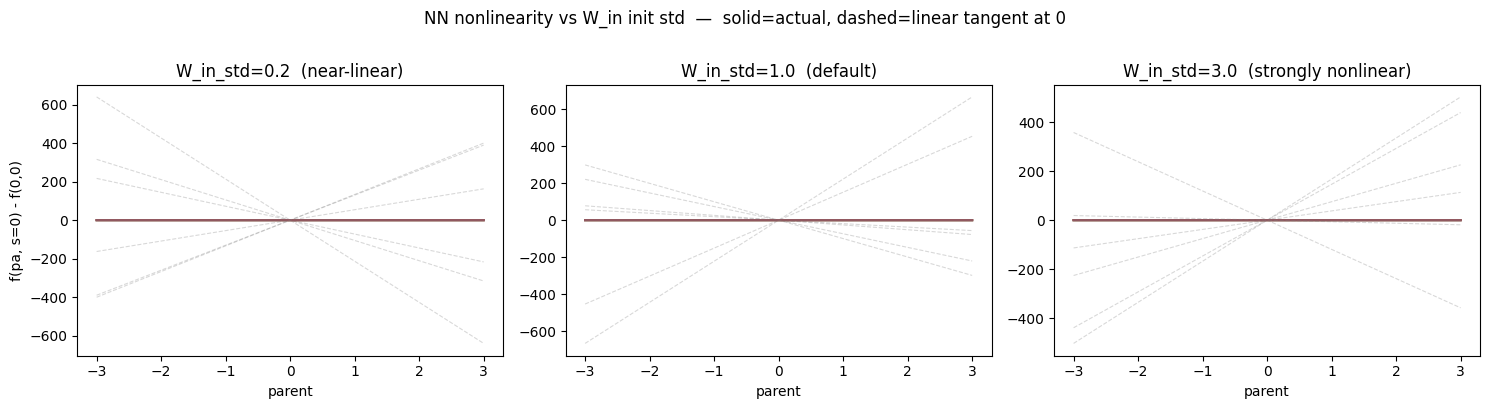

W_in_std   median_curvature
  0.2        0.00015
  1.0        0.00015
  3.0        0.00013


In [13]:
rng3 = np.random.default_rng(2)
N_DRAWS = 6

w1_configs = [
    (0.2,  'W_in_std=0.2  (near-linear)'),
    (1.0,  'W_in_std=1.0  (default)'),
    (3.0,  'W_in_std=3.0  (strongly nonlinear)'),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)

for ax, (std, label) in zip(axes, w1_configs):
    for _ in range(N_DRAWS):
        nn = NeuralNetMechanism(
            W_in=rng3.normal(0, std, (_N_HIDDEN, 1)),
            w_s=rng3.uniform(0.3, 0.7, _N_HIDDEN),
            b_in=np.zeros(_N_HIDDEN),
            hidden_weights=[rng3.normal(0, 1/np.sqrt(_N_HIDDEN), (_N_HIDDEN, _N_HIDDEN)) for _ in range(_N_DEPTH - 2)],
            hidden_biases=[np.zeros(_N_HIDDEN) for _ in range(_N_DEPTH - 2)],
            out_weight=rng3.uniform(0.3, 0.7, _N_HIDDEN) / _N_HIDDEN,
            ln_gamma=np.ones(_N_HIDDEN),
            ln_beta=np.zeros(_N_HIDDEN),
            c_s=float(rng3.uniform(0.3, 0.7)),
        )
        y  = nn(x1d, s0)
        y0 = float(nn(np.zeros((1, 1)), np.zeros(1)))
        k  = slope_at_zero(nn)
        ax.plot(x1d.ravel(), y - y0,          alpha=0.7)
        ax.plot(x1d.ravel(), k * x1d.ravel(),  alpha=0.3, lw=0.8, ls='--', color='gray')
    ax.set_title(label)
    ax.set_xlabel('parent')

axes[0].set_ylabel('f(pa, s=0) - f(0,0)')
fig.suptitle('NN nonlinearity vs W_in init std  —  solid=actual, dashed=linear tangent at 0', y=1.01)
plt.tight_layout()
plt.show()

# Print median curvature for each regime
print('W_in_std   median_curvature')
for std, label in w1_configs:
    curv = []
    for _ in range(200):
        nn = NeuralNetMechanism(
            W_in=rng3.normal(0, std, (_N_HIDDEN, 1)),
            w_s=rng3.uniform(0.3, 0.7, _N_HIDDEN),
            b_in=np.zeros(_N_HIDDEN),
            hidden_weights=[rng3.normal(0, 1/np.sqrt(_N_HIDDEN), (_N_HIDDEN, _N_HIDDEN)) for _ in range(_N_DEPTH - 2)],
            hidden_biases=[np.zeros(_N_HIDDEN) for _ in range(_N_DEPTH - 2)],
            out_weight=rng3.uniform(0.3, 0.7, _N_HIDDEN) / _N_HIDDEN,
            ln_gamma=np.ones(_N_HIDDEN),
            ln_beta=np.zeros(_N_HIDDEN),
            c_s=float(rng3.uniform(0.3, 0.7)),
        )
        curv.append(mean_abs_curvature(nn, x1d, s0))
    print(f'  {std:.1f}        {np.median(curv):.5f}')